# r/InvestmentClub Community Analysis

In [1]:
pip install -r requirements.txt

  Using cached vaderSentiment-3.3.2-py2.py3-none-any.whl.metadata (572 bytes)
Using cached vaderSentiment-3.3.2-py2.py3-none-any.whl (125 kB)
Note: you may need to restart the kernel to use updated packages.


#### In this Notebook we will be looking at the community interaction that is happening in the subreddit `r/InvestmentClub` 

##### We have two datasets in JSON format
##### `InvestmentClub_submission_refined.json`- This contains the Reddit Posts
##### `InvestmentClub_comment_refined.json` -  This contains the Comments to the Reddit Posts / Replying  to Comments

## Importing Libraries

In [2]:
import numpy as np
import pandas as pd
import networkx as nx
import matplotlib.pyplot as plt
import seaborn as sns
import json
import re
from datetime import datetime, timezone
from collections import Counter
from vaderSentiment.vaderSentiment import SentimentIntensityAnalyzer
from networkx.algorithms import community
from networkx.algorithms.community.quality import modularity
from sklearn.ensemble import IsolationForest
import random


## Reading the dataset 

In [3]:
# Load JSON data
def load_json(filename):
    with open(filename, "r", encoding="utf-8") as file:
        return json.load(file)


In [4]:
## Submissions are the Originals Posts 
submissions = load_json(r"Data\\InvestmentClub_submissions_refined.json")

## Comments are like the "replies" to these posts
comments = load_json(r"Data\\InvestmentClub_comments_refined.json")

### Checking if the JSON files have been loaded properly

In [5]:
submissions

[{'downs': 2,
  'link_flair_text': None,
  'distinguished': None,
  'media': None,
  'url': 'http://www.reddit.com/r/InvestmentClub/comments/p6vn4/goog_buy_when_at_or_around_575_short_when_it_is/',
  'link_flair_css_class': None,
  'id': 'p6vn4',
  'edited': False,
  'num_reports': None,
  'created_utc': 1328140326,
  'banned_by': None,
  'name': 't3_p6vn4',
  'subreddit': 'InvestmentClub',
  'title': 'GOOG. Buy when at or around 575. Short when it is around 615.',
  'author_flair_text': None,
  'is_self': True,
  'author': 'oblivious_human',
  'media_embed': {},
  'permalink': '/r/InvestmentClub/comments/p6vn4/goog_buy_when_at_or_around_575_short_when_it_is/',
  'author_flair_css_class': None,
  'selftext': '',
  'domain': 'self.InvestmentClub',
  'num_comments': 2,
  'likes': None,
  'clicked': False,
  'thumbnail': 'default',
  'saved': False,
  'subreddit_id': 't5_2tfzh',
  'ups': 5,
  'approved_by': None,
  'score': 3,
  'selftext_html': '&lt;!-- SC_OFF --&gt;&lt;div class="md"&gt

In [6]:
comments

[{'controversiality': 0,
  'downs': 0,
  'id': 'c3mvgkg',
  'score': 2,
  'score_hidden': False,
  'name': 't1_c3mvgkg',
  'edited': False,
  'body': 'I think this is a great idea!',
  'subreddit_id': 't5_2tfzh',
  'created_utc': '1328119996',
  'gilded': 0,
  'author_flair_css_class': None,
  'ups': 2,
  'retrieved_on': 1428278429,
  'parent_id': 't3_p6dut',
  'author_flair_text': None,
  'link_id': 't3_p6dut',
  'author': 'hobbitskill',
  'archived': True,
  'subreddit': 'InvestmentClub',
  'distinguished': None},
 {'controversiality': 0,
  'downs': 0,
  'id': 'c3mvhfc',
  'score': 1,
  'score_hidden': False,
  'name': 't1_c3mvhfc',
  'edited': False,
  'body': 'what he/she said^!!',
  'subreddit_id': 't5_2tfzh',
  'created_utc': '1328120116',
  'gilded': 0,
  'author_flair_css_class': None,
  'ups': 1,
  'retrieved_on': 1428278436,
  'parent_id': 't1_c3mvgkg',
  'author_flair_text': None,
  'link_id': 't3_p6dut',
  'author': 'withacupofcoffee',
  'archived': True,
  'subreddit': 'In

## Processing the data

In [7]:
## Making the submissions into a dataframe

def process_submissions(submissions):
    data = []
    for submission in submissions:
        data.append({
            "url": submission.get("url"),
            "id": submission.get("id"),
            "parent_id": submission.get("parent_id"),
            "name": submission.get("name"),  
            "title": submission.get("title"),
            "author": submission.get("author"),
            "num_comments": submission.get("num_comments"),
            "created_utc": submission.get("created_utc"),
            "score": submission.get("score"),
            "ups": submission.get("ups"),
            "downs": submission.get("downs"),
            "clicked": submission.get("clicked"),
            "banned_by": submission.get("banned_by"),
            "self_text": submission.get("selftext"),  
            "body": submission.get("body", ""),  
        })
    return pd.DataFrame(data)

In [8]:
## Making the comments into a dataframe

def process_comments(comments):
    data = []
    for comment in comments:
        data.append({
            "id": comment.get("id"),
            "parent_id": comment.get("parent_id"),
            "name": comment.get("name"),  
            "author": comment.get("author"),
            "body": comment.get("body", ""), 
            "created_utc": comment.get("created_utc"),
            "score": comment.get("score"),
            "ups": comment.get("ups"),
            "downs": comment.get("downs"),
            "clicked": comment.get("clicked"),
            "banned_by": comment.get("banned_by"),
            "self_text": comment.get("selftext") ,
            "link_id" : comment.get("link_id")
        })
    return pd.DataFrame(data)

In [9]:
submissions_df = process_submissions(submissions)
comments_df = process_comments(comments)

In [10]:
submissions_df

,url,id,parent_id,name,title,author,num_comments,created_utc,score,ups,downs,clicked,banned_by,self_text,body
0,http://www.reddit.com/r/InvestmentClub/comment...,p6vn4,None,t3_p6vn4,GOOG. Buy when at or around 575. Short when it...,oblivious_human,2,1328140326,3,5,2,False,None,,
1,http://www.reddit.com/r/InvestmentClub/comment...,p6uck,None,t3_p6uck,We need to set some goals!,kilzorthekilbot,1,1328138637,6,7,1,False,None,"Hey everyone,\n\nThis reddit seems like a real...",
2,http://www.reddit.com/r/InvestmentClub/comment...,p6u55,None,t3_p6u55,Lets add some risk...,cantquitereddit,4,1328138362,0,1,4,False,None,How about a start up company traded on a small...,
3,http://www.reddit.com/r/InvestmentClub/comment...,p6r70,None,t3_p6r70,InterActive Corp (IACI),ttg314,12,1328134776,4,9,5,False,None,Are you a fan of College Humor videos?\nDo you...,
4,http://www.reddit.com/r/InvestmentClub/comment...,p6qgm,None,t3_p6qgm,AGNC - 20% yield anyone?,Waterwoo,13,1328133998,4,9,5,False,None,"This is a pretty simple suggestion, but some o...",
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
18966,https://www.reddit.com/r/InvestmentClub/commen...,zzp016,None,t3_zzp016,RENTING/BUYING PERSONAL INVESTOR DATABASE,Rachel_68,0,1672473791,1,1,0,False,None,[removed],
18967,https://youtube.com/watch?v=DwM78lCdvr8&amp;fe...,zztx5h,None,t3_zztx5h,Earn 5% Profit Daily on Tether USDT Investment...,New-Procedure-3006,0,1672492606,1,1,0,False,None,,
18968,https://www.reddit.com/r/InvestmentClub/commen...,zzvb9q,None,t3_zzvb9q,High yield dividend stocks,yukardo,0,1672497065,1,1,0,False,None,[removed],
18969,https://serebrisky.com/2022/12/29/economic-and...,1000s3h,None,t3_1000s3h,Economic and investment outlook for 2023 by to...,diegosere,4,1672512399,27,1,0,False,None,,


In [11]:
comments_df

,id,parent_id,name,author,body,created_utc,score,ups,downs,clicked,banned_by,self_text,link_id
0,c3mvgkg,t3_p6dut,t1_c3mvgkg,hobbitskill,I think this is a great idea!,1328119996,2,2,0,None,None,None,t3_p6dut
1,c3mvhfc,t1_c3mvgkg,t1_c3mvhfc,withacupofcoffee,what he/she said^!!,1328120116,1,1,0,None,None,None,t3_p6dut
2,c3mw780,t3_p6dut,t1_c3mw780,hobbitskill,"Which simulator are you going to use, the only...",1328123651,1,1,0,None,None,None,t3_p6dut
3,c3mwiu4,t1_c3mw780,t1_c3mwiu4,Zurevu,It depends on everybody's vote but I'm guessin...,1328125289,1,1,0,None,None,None,t3_p6dut
4,c3mwngt,t3_p6jm5,t1_c3mwngt,AutonomousMonkey,Ticker: CHK,1328125916,2,2,0,None,None,None,t3_p6jm5
...,...,...,...,...,...,...,...,...,...,...,...,...,...
22858,j2f4uul,t3_zwlyan,t1_j2f4uul,Zurevu,Would you mind reposting or crossposting this ...,1672518352,1,2,0,None,None,None,t3_zwlyan
22859,j2fenq1,t3_zwd9iw,t1_j2fenq1,Aurelian276,I share your sentiments. When you invest in so...,1672522660,1,2,0,None,None,None,t3_zwd9iw
22860,j2fjx9w,t3_z3igew,t1_j2fjx9w,Flip-In-StocksGang,POWW,1672524982,1,2,0,None,None,None,t3_z3igew
22861,j2fl2px,t3_10053am,t1_j2fl2px,InvestmentClub-ModTeam,Your post was removed because it is about a sp...,1672525489,1,2,0,None,None,None,t3_10053am


In [12]:
comments_df["link_id"]

0          t3_p6dut
1          t3_p6dut
2          t3_p6dut
3          t3_p6dut
4          t3_p6jm5
            ...    
22858     t3_zwlyan
22859     t3_zwd9iw
22860     t3_z3igew
22861    t3_10053am
22862    t3_1000s3h
Name: link_id, Length: 22863, dtype: object

## Understanding our dataframes

We know 

-> `submissions_df` refers to the the number of posts on the subreddit and 

-> `comments_df`  refers to the number of comments on the subreddit (this could be `t3_` tagged which refers to a comment replying to a submission or `t1_` tagged which refers to a comment replying to a comment)(the `link_id` attribute refers to the orginal post)

In [13]:
# Check for duplicate values in the 'id' column
duplicate_ids = submissions_df['id'].duplicated().sum()

# Print the number of duplicate IDs
print(f"Number of duplicate IDs: {duplicate_ids}")

Number of duplicate IDs: 0


## Merging the datasets

In [14]:
# Extract submission IDs from comment_link_id (remove 't3_' prefix)
comments_df["link_id"] = comments_df["link_id"].str.extract(r"t3_(.*)")

# Ensure submission_id in submissions_df doesn't have 't3_' prefix
submissions_df["id"] = submissions_df["id"].str.replace(r"^t3_", "", regex=True)

# Merge using submission_link_id
merged_df = comments_df.merge(
    submissions_df, left_on="link_id", right_on="id", how="left"
)



In [15]:
merged_df

,id_x,parent_id_x,name_x,author_x,body_x,created_utc_x,score_x,ups_x,downs_x,clicked_x,...,author_y,num_comments,created_utc_y,score_y,ups_y,downs_y,clicked_y,banned_by_y,self_text_y,body_y
0,c3mvgkg,t3_p6dut,t1_c3mvgkg,hobbitskill,I think this is a great idea!,1328119996,2,2,0,None,...,Zurevu,23,1328118981,16,18,2,False,None,,
1,c3mvhfc,t1_c3mvgkg,t1_c3mvhfc,withacupofcoffee,what he/she said^!!,1328120116,1,1,0,None,...,Zurevu,23,1328118981,16,18,2,False,None,,
2,c3mw780,t3_p6dut,t1_c3mw780,hobbitskill,"Which simulator are you going to use, the only...",1328123651,1,1,0,None,...,Zurevu,23,1328118981,16,18,2,False,None,,
3,c3mwiu4,t1_c3mw780,t1_c3mwiu4,Zurevu,It depends on everybody's vote but I'm guessin...,1328125289,1,1,0,None,...,Zurevu,23,1328118981,16,18,2,False,None,,
4,c3mwngt,t3_p6jm5,t1_c3mwngt,AutonomousMonkey,Ticker: CHK,1328125916,2,2,0,None,...,AutonomousMonkey,14,1328125906,1,8,7,False,None,I'm pitching Chesapeake Energy due to it's gro...,
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
22858,j2f4uul,t3_zwlyan,t1_j2f4uul,Zurevu,Would you mind reposting or crossposting this ...,1672518352,1,2,0,None,...,Happy-Car3439,4,1672164653,2,1,0,False,None,In this video Mohnish Pabrai is speaking about...,
22859,j2fenq1,t3_zwd9iw,t1_j2fenq1,Aurelian276,I share your sentiments. When you invest in so...,1672522660,1,2,0,None,...,WendBack,2,1672139442,7,1,0,False,None,,
22860,j2fjx9w,t3_z3igew,t1_j2fjx9w,Flip-In-StocksGang,POWW,1672524982,1,2,0,None,...,Wheelsonthegreenbus,1,1669292149,7,1,0,False,None,,
22861,j2fl2px,t3_10053am,t1_j2fl2px,InvestmentClub-ModTeam,Your post was removed because it is about a sp...,1672525489,1,2,0,None,...,Flip-In-StocksGang,1,1672524940,2,1,0,False,None,[removed],


## Data Summary 

In [16]:
# Fix date handling
submissions_df['created_utc'] = pd.to_datetime(submissions_df['created_utc'], unit='s')
comments_df['created_utc'] = pd.to_datetime(comments_df['created_utc'], unit='s')

C:\Users\vaghe\AppData\Local\Temp\ipykernel_26388\4110817280.py:2: FutureWarning: The behavior of 'to_datetime' with 'unit' when parsing strings is deprecated. In a future version, strings will be parsed as datetime strings, matching the behavior without a 'unit'. To retain the old behavior, explicitly cast ints or floats to numeric type before calling to_datetime.
  submissions_df['created_utc'] = pd.to_datetime(submissions_df['created_utc'], unit='s')
C:\Users\vaghe\AppData\Local\Temp\ipykernel_26388\4110817280.py:3: FutureWarning: The behavior of 'to_datetime' with 'unit' when parsing strings is deprecated. In a future version, strings will be parsed as datetime strings, matching the behavior without a 'unit'. To retain the old behavior, explicitly cast ints or floats to numeric type before calling to_datetime.
  comments_df['created_utc'] = pd.to_datetime(comments_df['created_utc'], unit='s')


### Duration of these posts and comments

In [17]:
# Compute time span of the posts
start_date = submissions_df['created_utc'].min()
end_date = submissions_df['created_utc'].max()
time_span = f"{start_date.date()} - {end_date.date()}"
days = (end_date - start_date).days
weeks = days / 7


In [18]:
# First and last submission dates
first_submission_date = submissions_df["created_utc"].min().date()
last_submission_date = submissions_df["created_utc"].max().date()

In [19]:
# Compute time span of comments
start_date_comments = comments_df['created_utc'].min()
end_date_comments = comments_df['created_utc'].max()
time_span_comments = f"{start_date_comments.date()} - {end_date_comments.date()}"
days_comments = (end_date_comments - start_date_comments).days
weeks_comments = days_comments / 7


In [20]:
# First and last comment dates
first_comment_date = comments_df["created_utc"].min().date()
last_comment_date = comments_df["created_utc"].max().date()

In [21]:
# Print results
print(f"First submission date: {first_submission_date}")
print(f"Last submission date: {last_submission_date}")
print(f"First comment date: {first_comment_date}")
print(f"Last comment date: {last_comment_date}")

First submission date: 2012-02-01
Last submission date: 2022-12-31
First comment date: 2012-02-01
Last comment date: 2022-12-31


## Count of posts as well as comments

In [22]:
# Total number of posts
total_posts = len(submissions_df)
total_posts

18971

In [23]:
# Total number of comments
total_of_comments = len(comments_df)
total_of_comments

22863

In [24]:
# Posts with replies
num_posts_with_replies = len(submissions_df[submissions_df["num_comments"] > 0])
posts_with_replies_percent = (num_posts_with_replies / total_posts) * 100


In [25]:
# Posts without replies
num_of_posts_without_replies = total_posts - num_posts_with_replies
posts_without_replies_percent = (num_of_posts_without_replies / total_posts) * 100

## User Counts and the Types of Users

In [26]:
# Total number of users
total_users = comments_df['author'].nunique()

In [27]:
# Get unique users from comments and submissions
comment_authors = set(comments_df["author"].dropna())
submission_authors = set(submissions_df["author"].dropna())

In [28]:
# Find the total unique users across both datasets
unique_users = comment_authors.union(submission_authors)

# Count them
num_unique_users = len(unique_users)


In [29]:
# Find users who commented but never posted
only_commenters = comment_authors - submission_authors

# Count them
num_only_commenters = len(only_commenters)


In [30]:
# Get unique users who posted submissions
num_posters = len(submission_authors)

In [31]:
# Find users who did both (intersection)
both_comment_and_post = comment_authors.intersection(submission_authors)

# Count them
num_both = len(both_comment_and_post)

In [32]:
# Print results
summary = {
    "Time span": time_span,
    "Days": days,
    "Weeks": weeks,
    "Total Posts": total_posts,
    "Posts with replies (%)": f"{num_posts_with_replies} ({posts_with_replies_percent:.1f}%)",
    "Posts without replies (%)": f"{num_of_posts_without_replies} ({posts_without_replies_percent:.1f}%)",
    "Total number of unique users ": num_unique_users,
    "Total number of people who made a submission ": num_posters,
    "Total number of people who have commented and posted ": num_both,
    "Users who commented but never posted": num_only_commenters,
}


In [33]:
summary_df = pd.DataFrame(list(summary.items()), columns=["Metric", "Value"])
summary_df.tail(5)

,Metric,Value
5,Posts without replies (%),12720 (67.0%)
6,Total number of unique users,12919
7,Total number of people who made a submission,6986
8,Total number of people who have commented and ...,1293
9,Users who commented but never posted,5933


### BUT

In [34]:
x = set(merged_df["author_x"])
y = set(merged_df["author_y"])

z = x.union(y)

len(z)

8898

##### There are comments that haven't been recorded in the `InvestmentClub_comment_refined.json file`

## Network Analysis

In [35]:
# Group by author and count their total posts
user_post_counts = submissions_df['author'].value_counts()

# Define super user threshold (top 5% active users)
threshold = user_post_counts.quantile(0.95)

# Filter super users
super_users = user_post_counts[user_post_counts >= threshold]

# Convert to DataFrame for better readability
df_super_users = super_users.reset_index()
df_super_users.columns = ["User", "Total Posts"]

# Display the top super users
print(df_super_users)

                 User  Total Posts
0              Zurevu         2064
1           [deleted]         2062
2          The-Techie          551
3           Ituglobal          141
4    AESInternational          127
..                ...          ...
406    kacelamelfouad            5
407          Raiishin            5
408          Log_Many            5
409         luisarden            5
410             KeyBM            5

[411 rows x 2 columns]


In [36]:
# Create a directed graph
G = nx.DiGraph()

empty_count = 0

for _, row in merged_df.iterrows():
    submission_author = row.get("author_x")  # Author of the submission
    comment_author = row.get("author_y")  # Author of the comment

    # Skip rows where either author is missing
    if pd.isna(submission_author) or pd.isna(comment_author):
        empty_count += 1
        continue  

    # Allow self-loops (users commenting on their own posts)
    G.add_node(submission_author, type="user")
    G.add_node(comment_author, type="user")
    G.add_edge(comment_author, submission_author)  # Commenter → Post author

In [37]:
print(f"Number of nodes: {G.number_of_nodes()}, Number of edges: {G.number_of_edges()}")

Number of nodes: 8898, Number of edges: 13847


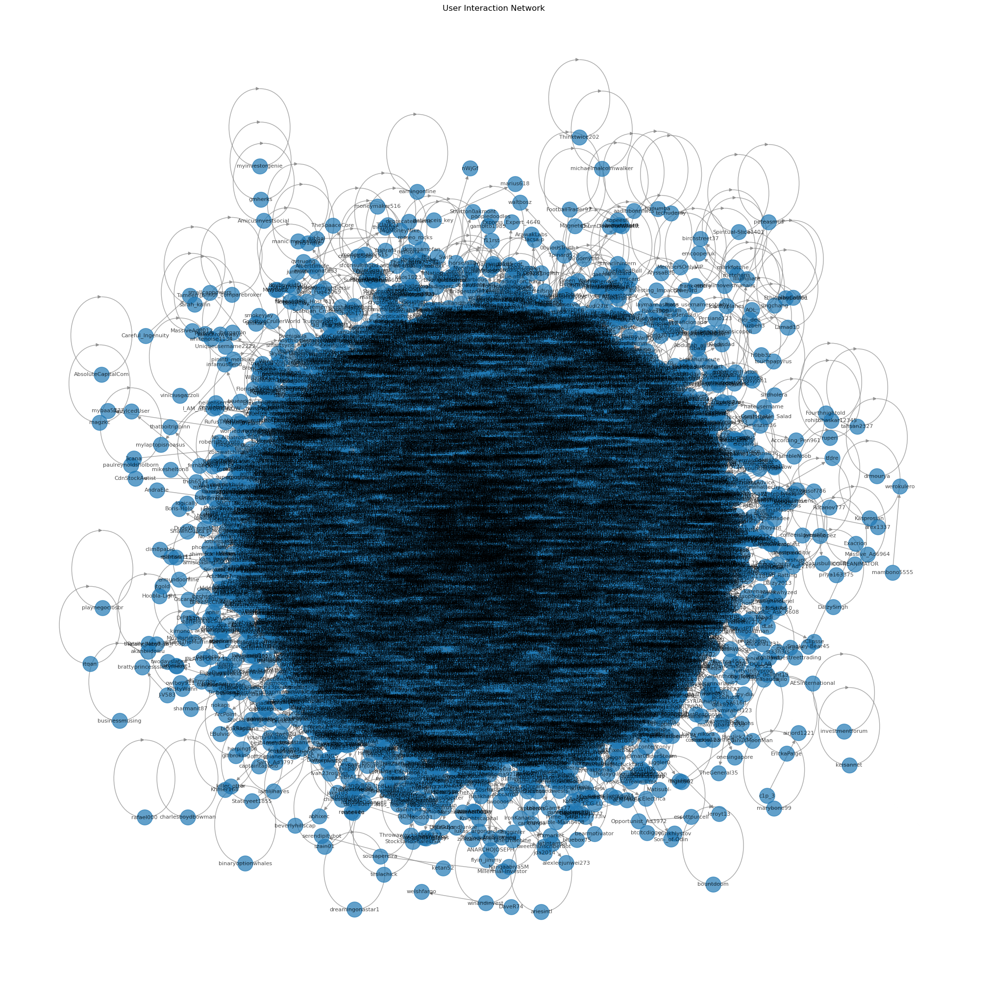

In [38]:
plt.figure(figsize=(20, 20))
pos = nx.spring_layout(G, k=5)  # Spread out nodes
nx.draw(G, pos, with_labels=True, node_size=500, font_size=8, edge_color="gray", alpha=0.7)
plt.title("User Interaction Network ")
plt.show()

### This is too large to understand what is going on , so let's take the top 100

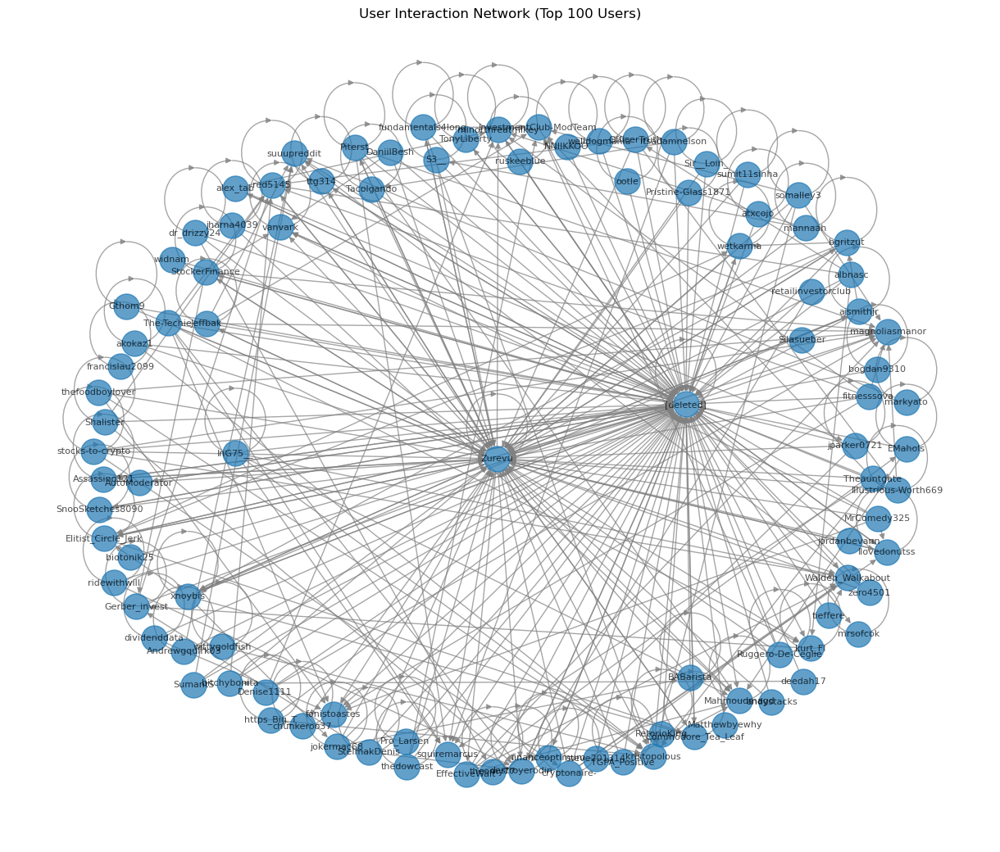

In [39]:
# Keep only the top 100 most connected users
top_users = [user for user, degree in sorted(G.degree(), key=lambda x: x[1], reverse=True)[:100]]
G_small_100 = G.subgraph(top_users)

plt.figure(figsize=(12, 10))
pos = nx.spring_layout(G_small_100, k=2)  
nx.draw(G_small_100, pos, with_labels=True, node_size=500, font_size=8, edge_color="gray", alpha=0.7)
plt.title("User Interaction Network (Top 100 Users)")
plt.show()


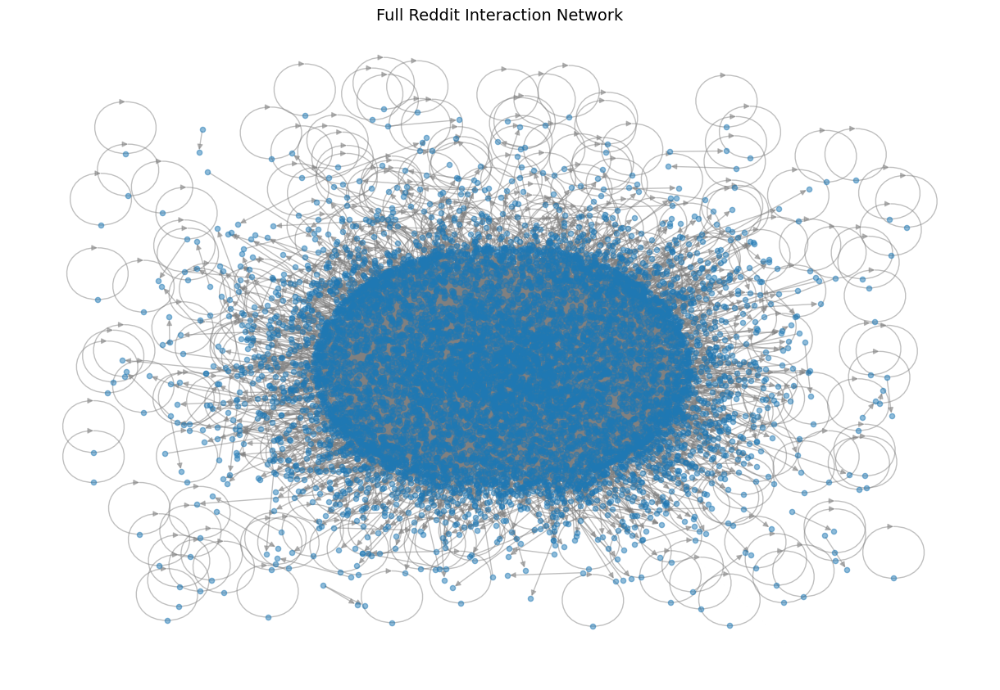

In [40]:
# Plot full network with labels
degree_centrality = nx.degree_centrality(G)
plt.figure(figsize=(12, 8))
nx.draw(G, node_size=20, edge_color='gray', alpha=0.5, with_labels=False)
plt.title("Full Reddit Interaction Network", fontsize=14)
plt.show()


### A Deeper Look at the community 

### Let's look at a few of the most influential users

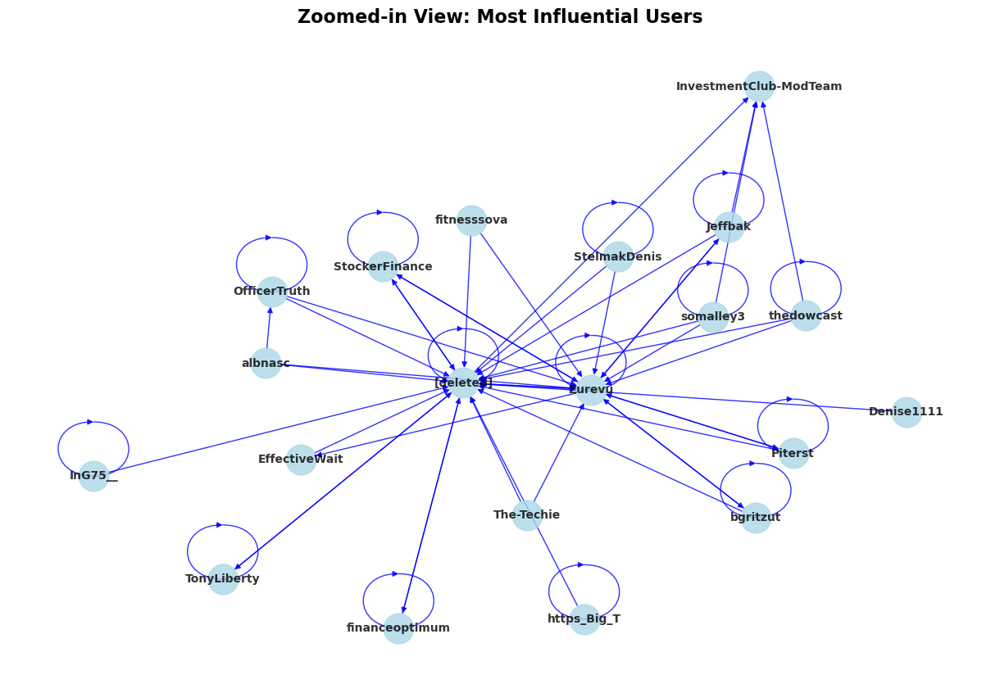

In [41]:
# Extract top 20 most influential users by degree centrality
largest_nodes = sorted(degree_centrality, key=degree_centrality.get, reverse=True)[:20]
subG = G.subgraph(largest_nodes)

plt.figure(figsize=(12, 8))  # Larger figure size

# Use spring layout with more spacing
pos = nx.spring_layout(subG, k=0.8, seed=42)  # Adjust k for spacing

# Draw the graph
nx.draw(subG, pos, 
        node_size=700,  # Larger nodes
        edge_color='blue', 
        with_labels=True, 
        font_size=10,  # Larger font size
        font_weight='bold', 
        node_color='lightblue', 
        alpha=0.8)

plt.title("Zoomed-in View: Most Influential Users", fontsize=16, fontweight='bold')
plt.show()

### Let's look at top user interactions in the community

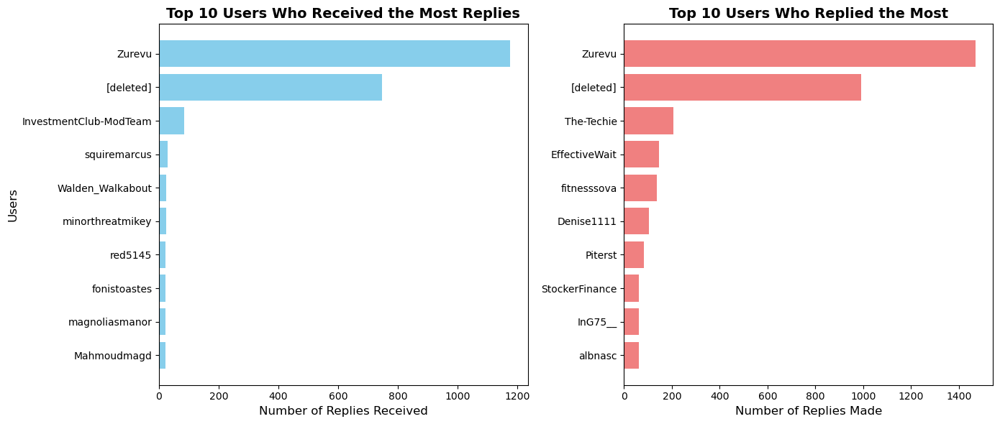

In [42]:
# Get the top 10 users who received the most replies (in-degree)
top_replied_users = sorted(G.in_degree(), key=lambda x: x[1], reverse=True)[:10]
users_received, replies_received = zip(*top_replied_users)  # Extract names & counts

# Get the top 10 users who replied the most (out-degree)
top_repliers = sorted(G.out_degree(), key=lambda x: x[1], reverse=True)[:10]
users_replied, replies_made = zip(*top_repliers)  # Extract names & counts

# Create side-by-side bar charts
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# Bar chart: Users who received the most replies
axes[0].barh(users_received[::-1], replies_received[::-1], color='skyblue')
axes[0].set_title("Top 10 Users Who Received the Most Replies", fontsize=14, fontweight='bold')
axes[0].set_xlabel("Number of Replies Received", fontsize=12)
axes[0].set_ylabel("Users", fontsize=12)
axes[0].tick_params(axis='y', labelsize=10)

# Bar chart: Users who replied the most
axes[1].barh(users_replied[::-1], replies_made[::-1], color='lightcoral')
axes[1].set_title("Top 10 Users Who Replied the Most", fontsize=14, fontweight='bold')
axes[1].set_xlabel("Number of Replies Made", fontsize=12)
axes[1].tick_params(axis='y', labelsize=10)

plt.tight_layout()
plt.show()

##### It seems that "deleted " , "InvestmentClubModTeam" , "Zurevru" seem to be the users mostly interacted with

##### But we cannot infer much important data from "deleted" because Reddit gives "deleted" to any and every user who has deleted their accounts , so this could be either a person or a group of people

# Further Analysis of the network

### Research Question 1) 
#### "What is the distribution of participation? (Do most users comment once, or are there a few very active users?)

In [43]:
# Count number of comments per user
user_comment_counts = comments_df["author"].value_counts()

In [44]:
# Compute statistics
mean_comments = user_comment_counts.mean()
median_comments = user_comment_counts.median()
top_1_percent = user_comment_counts.quantile(0.99)  # 99th percentile users

In [45]:
print(f"Total unique commenters: {len(user_comment_counts)}")
print(f"Mean comments per user: {mean_comments:.2f}")
print(f"Median comments per user: {median_comments}")
print(f"99th percentile users comment at least {int(top_1_percent)} times")

Total unique commenters: 7226
Mean comments per user: 3.16
Median comments per user: 1.0
99th percentile users comment at least 20 times


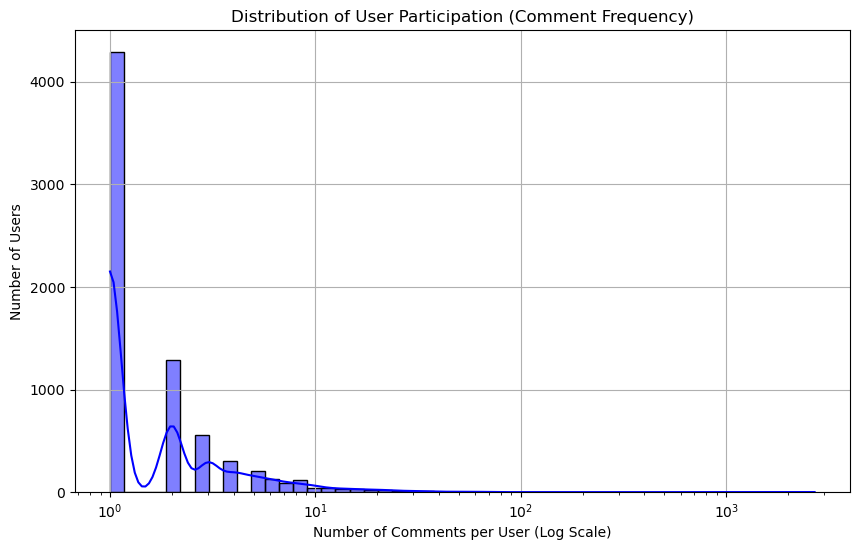

In [46]:
# Visualization
plt.figure(figsize=(10,6))
sns.histplot(user_comment_counts, bins=50, log_scale=True, kde=True, color='blue')

plt.xlabel("Number of Comments per User (Log Scale)")
plt.ylabel("Number of Users")
plt.title("Distribution of User Participation (Comment Frequency)")
plt.grid(True)
plt.show()


### Final Thoughts

#### Many users just participate once.The long tail distribution shows that most users post very few comments, while a few users comment a lot.

## Research Question 2) 
###  Do rich-club users control most of the discussion?

In [47]:
# Convert directed graph to undirected
G_undirected = G.to_undirected()

# Remove self-loops
G_undirected.remove_edges_from(nx.selfloop_edges(G_undirected))

# Compute rich-club coefficient
rich_club = nx.rich_club_coefficient(G_undirected, normalized=True)


In [48]:
degree_dict = dict(G.degree())
threshold = np.percentile(list(degree_dict.values()), 99)  # Users in the 99th percentile
rich_users = [user for user, deg in degree_dict.items() if deg >= threshold]

In [49]:
rich_comments = comments_df[comments_df["author"].isin(rich_users)]
percentage_comments = len(rich_comments) / len(comments_df) * 100
print(f"Rich-club users contribute {percentage_comments:.2f}% of all comments.")


Rich-club users contribute 28.12% of all comments.


In [50]:
rich_submissions = submissions_df[submissions_df["author"].isin(rich_users)]
percentage_submissions = len(rich_submissions) / len(submissions_df) * 100
print(f"Rich-club users create {percentage_submissions:.2f}% of all submissions.")


Rich-club users create 33.63% of all submissions.


In [51]:
rich_in_degree = sum(dict(G.in_degree(rich_users)).values()) / G.number_of_edges() * 100
rich_out_degree = sum(dict(G.out_degree(rich_users)).values()) / G.number_of_edges() * 100
print(f"Rich users receive {rich_in_degree:.2f}% of all replies and send {rich_out_degree:.2f}% of all replies.")


Rich users receive 17.50% of all replies and send 39.93% of all replies.


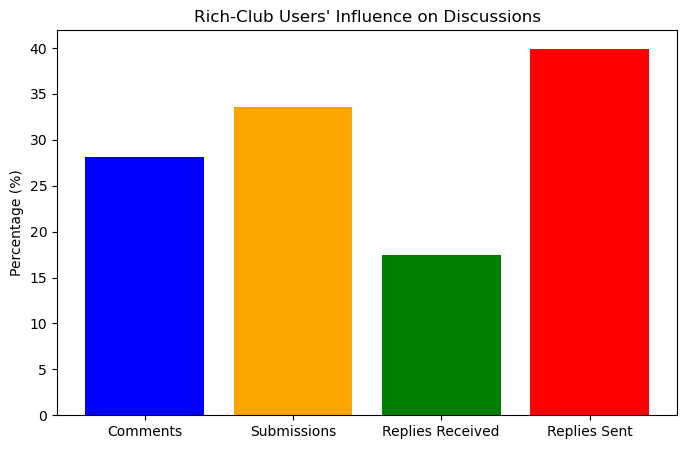

In [52]:
categories = ["Comments", "Submissions", "Replies Received", "Replies Sent"]
values = [percentage_comments, percentage_submissions, rich_in_degree, rich_out_degree]

plt.figure(figsize=(8,5))
plt.bar(categories, values, color=["blue", "orange", "green", "red"])
plt.ylabel("Percentage (%)")
plt.title("Rich-Club Users' Influence on Discussions")
plt.show()

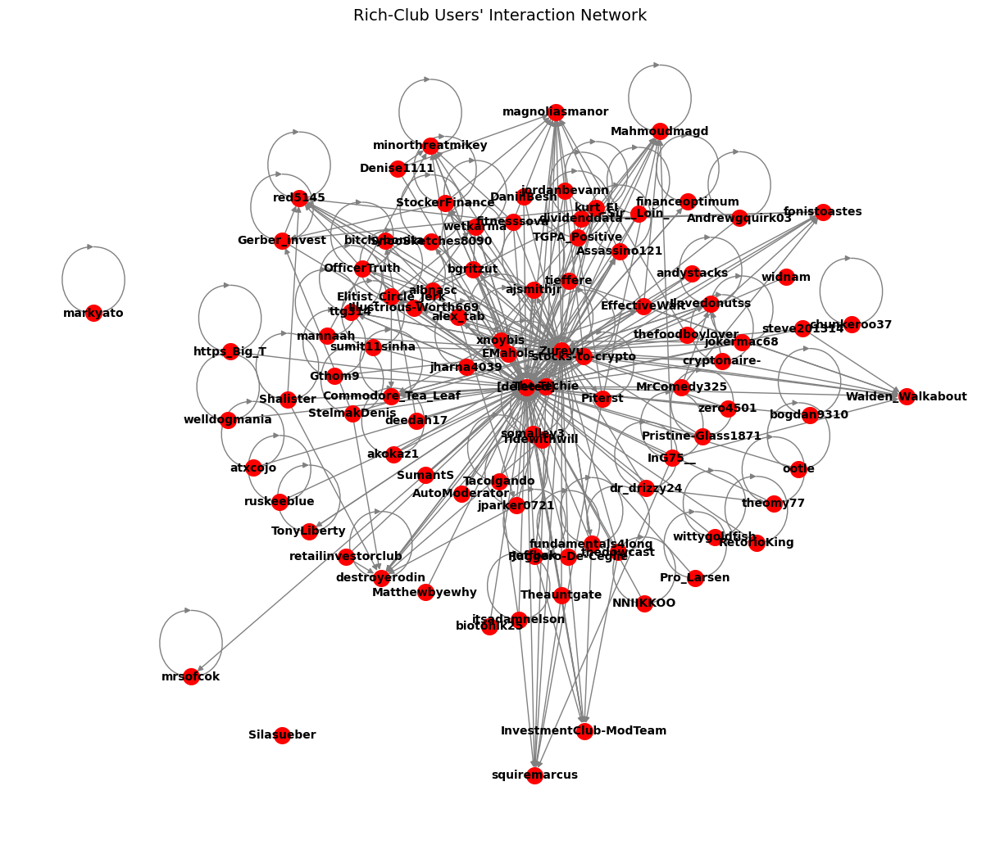

In [53]:
# Extract subgraph of rich-club users
subG = G.subgraph(rich_users)

# Define a spring layout for better spacing
pos = nx.spring_layout(subG, k=0.5)  # Adjust k for spacing

# Plot the graph with better visualization settings
plt.figure(figsize=(12, 10))  # Increase figure size
nx.draw(subG, pos, 
        node_color="red", 
        edge_color="gray", 
        node_size=200,  # Increase node size
        with_labels=True, 
        font_size=10,  # Increase font size
        font_weight="bold")  # Make labels more readable

# Title and display
plt.title("Rich-Club Users' Interaction Network", fontsize=14)
plt.show()


### Final Thoughts

##### Rich-club users play a significant role in discussions, contributing `28.12%` of all comments and `33.63%` of all submissions, indicating their strong influence in shaping conversations. They are highly engaged, sending `39.93%` of all replies, which suggests they actively drive discussions. However, they receive only `17.50%` of replies, implying that while they contribute heavily, they do not dominate all interactions. The network visualization shows a densely connected core, suggesting a tightly knit group that interacts frequently. This raises questions about whether these users create an "elite circle" that steers discussions or if their influence remains balanced across the community.









## Research Question 3) 
### "How active is the subreddit with respect to time ? "

In [54]:
# Extract year and month
comments_df["year_month"] = comments_df["created_utc"].dt.to_period("M")
submissions_df["year_month"] = submissions_df["created_utc"].dt.to_period("M")

# Count the number of comments and submissions per month
comments_per_month = comments_df["year_month"].value_counts().sort_index()
submissions_per_month = submissions_df["year_month"].value_counts().sort_index()

# Merge comment and submission counts into one DataFrame
seasonality_df = pd.DataFrame({
    "comments": comments_per_month,
    "submissions": submissions_per_month
}).fillna(0)

# Convert period index to datetime for plotting
seasonality_df.index = seasonality_df.index.to_timestamp()


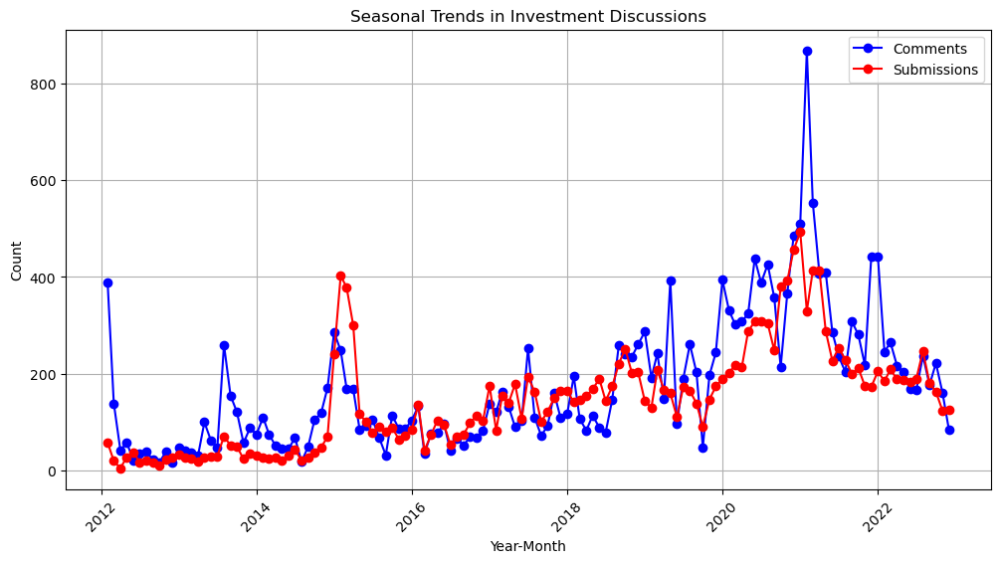

In [55]:
plt.figure(figsize=(12,6))
plt.plot(seasonality_df.index, seasonality_df["comments"], label="Comments", color="blue", marker="o")
plt.plot(seasonality_df.index, seasonality_df["submissions"], label="Submissions", color="red", marker="o")

plt.xlabel("Year-Month")
plt.ylabel("Count")
plt.title("Seasonal Trends in Investment Discussions")
plt.legend()
plt.grid(True)
plt.xticks(rotation=45)
plt.show()


### Final Thoughts

##### Some fluctuations appear regular across the years. For example: Early-year (Q1) spikes might indicate increased discussions around market forecasts, tax season, or New Year investment resolutions. Late-year dips (e.g., end of 2022) could be due to lower market activity during the holiday season.

## Open Creativity Task

### Let us perform sentimental analysis on the comments of the subreddit 

In [56]:
comments_file = "Data\\InvestmentClub_comments_refined.json" 
stopwords_file = "Data\\stopwordFile.txt" 

In [57]:
def load_json(file_path):
    with open(file_path, "r", encoding="utf-8") as file:
        data = json.load(file)
    return pd.DataFrame(data)

In [58]:
# Load stop words from the text file
def load_stopwords(file_path):
    with open(file_path, "r", encoding="utf-8") as file:
        stop_words = file.read().splitlines()  # Read lines and split into a list
    return set(stop_words)  # Convert to a set for faster lookup

In [59]:
stop_words = load_stopwords(stopwords_file)

In [60]:
# Function to clean text & remove stop words
def clean_text(text):
    if pd.isna(text) or text.strip() == "":
        return ""
    text = text.lower()  # Convert to lowercase
    text = re.sub(r"[^\w\s]", "", text)  # Remove punctuation
    words = text.split()
    filtered_words = [word for word in words if word not in stop_words]  # Remove stopwords
    return " ".join(filtered_words)

In [61]:
comments_df = load_json(comments_file)

In [62]:
comments_df["clean_body"] = comments_df["body"].apply(clean_text)

In [63]:
analyzer = SentimentIntensityAnalyzer()

In [64]:
# Function to get sentiment score
def get_sentiment(text):
    if text.strip() == "":
        return "Neutral"
    score = analyzer.polarity_scores(text)["compound"]
    if score >= 0.05:
        return "Positive"
    elif score <= -0.05:
        return "Negative"
    else:
        return "Neutral"


In [65]:
# Apply sentiment analysis
comments_df["sentiment"] = comments_df["clean_body"].apply(get_sentiment)

In [66]:
# Count sentiment distribution
sentiment_counts = comments_df["sentiment"].value_counts()
print("\nSentiment Distribution:")
print(sentiment_counts)


Sentiment Distribution:
sentiment
Positive    10393
Neutral      8968
Negative     3502
Name: count, dtype: int64


C:\Users\vaghe\AppData\Local\Temp\ipykernel_26388\3286766475.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=sentiment_counts.index, y=sentiment_counts.values, palette="coolwarm")


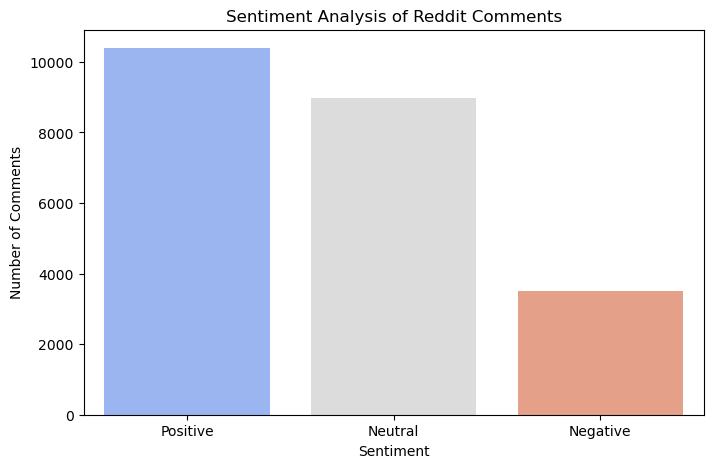

In [67]:
# Plot sentiment distribution
plt.figure(figsize=(8, 5))
sns.barplot(x=sentiment_counts.index, y=sentiment_counts.values, palette="coolwarm")
plt.title("Sentiment Analysis of Reddit Comments")
plt.xlabel("Sentiment")
plt.ylabel("Number of Comments")
plt.show()

### Q) How does sentiment fluctuate across discussions in the r/InvestmentClub subreddit, and what influence do superusers have in shaping it?

In [68]:
sia = SentimentIntensityAnalyzer()

# Function to calculate sentiment score
def get_sentiment(text):
    if pd.isna(text): 
        return None  # Handle missing values
    return sia.polarity_scores(text)['compound']  # VADER compound score

# Apply sentiment analysis
comments_df['sentiment'] = comments_df['body'].apply(get_sentiment)

# Identify Super Users (Top 10 users with most comments)
top_users = comments_df['author'].value_counts().head(10).index.tolist()

# Compare sentiment between super users and regular users
comments_df['is_super_user'] = comments_df['author'].apply(lambda x: x in top_users)

# Aggregate sentiment scores
super_user_sentiment = comments_df[comments_df['is_super_user']].groupby('author')['sentiment'].mean()
regular_user_sentiment = comments_df[~comments_df['is_super_user']]['sentiment'].mean()


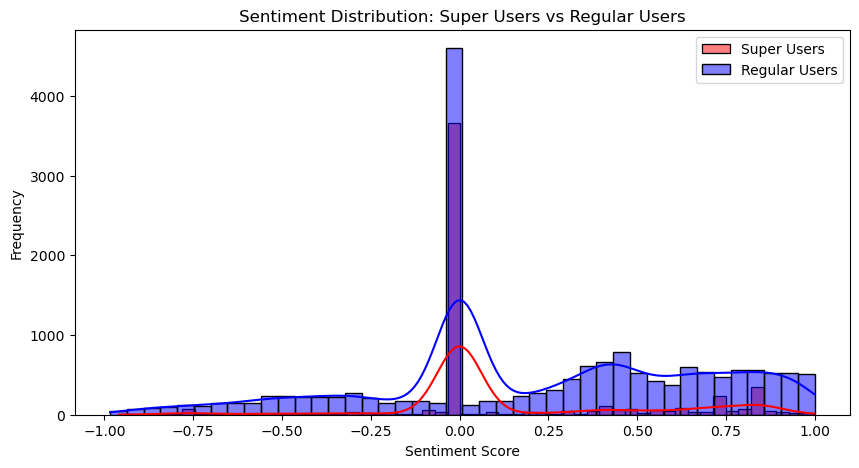

In [69]:
# Plot sentiment distribution
plt.figure(figsize=(10, 5))
sns.histplot(comments_df[comments_df['is_super_user']]['sentiment'], label='Super Users', color='red', kde=True)
sns.histplot(comments_df[~comments_df['is_super_user']]['sentiment'], label='Regular Users', color='blue', kde=True)
plt.xlabel('Sentiment Score')
plt.ylabel('Frequency')
plt.title('Sentiment Distribution: Super Users vs Regular Users')
plt.legend()
plt.show()

#### Super Users are more neutral and may act as moderators or experienced contributors with balanced views.
#### Regular Users express stronger emotions, both positive and negative, leading to more diverse and passionate discussions.
#### The subreddit appears to be mostly neutral or slightly positive in sentiment, with fewer negative extremes.

In [70]:
# Print Insights
print("Average Sentiment of Super Users:\n", super_user_sentiment)
print("\nOverall Average Sentiment of Regular Users:", regular_user_sentiment)

Average Sentiment of Super Users:
 author
InvestmentClub-ModTeam    0.391376
Jeffbak                   0.162200
StockTrendsBot           -0.738015
StockerFinance            0.532787
Walden_Walkabout          0.178570
Zurevu                    0.290635
[deleted]                 0.018646
ajsmithjr                 0.270542
evilbot666               -0.140269
minorthreatmikey          0.289510
Name: sentiment, dtype: float64

Overall Average Sentiment of Regular Users: 0.22827573806623744


#### Super users have mixed sentiment: Some like StockerFinance (0.535) and InvestmentClub-ModTeam (0.391) are more positive, while others like StockTrendsBot (-0.748) and evilbot666 (-0.137) lean negative.
#### Regular users have a lower but balanced sentiment (0.22): This suggests they contribute with neutral to slightly positive comments.
#### Super users influence sentiment trends: Highly active users may set the tone for discussions, amplifying either positive or negative emotions

### Final Thoughts

#### Regular Users are slightly more positive (0.220) compared to some Super Users.
#### Super Users exhibit a wider sentiment range, with some being highly positive and others more negative.

# Conclusion

#### We had proposed 4 research questions to get insights into the community of `r/InvestmentClub`